# Virtual temperature sensor for an EV motor: modelling notebook

**Problem.** The permanent magnets in an electric-vehicle motor (PMSM) are damaged for good if they overheat, but a car cannot
measure the temperature of a rotor spinning at 6,000 rpm. The goal is a **virtual sensor**: estimate the magnet temperature and three
stator temperatures from signals a car *can* measure (currents, voltages, speed, coolant and ambient temperature). Torque is
deliberately **not** used, because a production car cannot measure it reliably.

**Data.** Paderborn University (LEA) PMSM test bench, *Electric Motor Temperature* (Kaggle, CC-BY-SA-4.0): 69 drive cycles,
185 hours, 2 Hz.

**Metric.** As in the published benchmark: MSE in K² averaged over the four temperatures, plus the worst-case absolute error (K),
on the authors' held-out generalization cycles **60, 62, 74**.

| Model | Test MSE (K²) | Worst case (K) | Torque input |
|---|---|---|---|
| Best published model (Thermal Neural Network, EAAI 2023) | 2.87 | 6.02 | yes |
| **This notebook: ridge + start correction, averaged with a TNN** | **1.50** | **5.73** | **no** |

**Plan.** EDA → why load *history* matters → features → validation strategy → ridge → start-of-run correction →
Thermal Neural Network → ensemble → the hot-restart finding → error analysis.

In [1]:
import json, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GroupKFold, KFold

import os, sys
sys.path.insert(0, os.path.abspath(".."))   # project root, so the notebook reuses the tested project code
from src.data import (load, make_features, add_physics_features, MEASURABLE, TARGETS,
                      TEST_PROFILES, SAMPLE_RATE_HZ, ROOT)
from src.seq_model import VAL_PROFILES
from src.select_cv import SPAN_SETS
from src.start_correction import ridge, correct, initial_temps
from src.compare import tnn_predict
from src.metrics import PUBLISHED
from src import tnn as T

%matplotlib inline
warnings.filterwarnings("ignore")   # src.compare switches matplotlib to Agg when imported; the magic above restores inline plots
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False})
NAMES = {"pm": "magnet", "stator_yoke": "stator yoke", "stator_tooth": "stator tooth", "stator_winding": "stator winding"}

def score(P, Y):
    e = P - Y
    return {"MSE avg (K²)": round(float((e ** 2).mean()), 2), "MSE magnet (K²)": round(float((e[:, 0] ** 2).mean()), 2),
            "worst case (K)": round(float(np.abs(e).max()), 2)}

## 1. The data

In [2]:
raw = load()
df = add_physics_features(raw)
dur_min = raw.groupby("profile_id").size() / SAMPLE_RATE_HZ / 60
train_p = [p for p in sorted(raw.profile_id.unique()) if p not in TEST_PROFILES + VAL_PROFILES]
print(f"{len(raw):,} rows x {raw.shape[1]} columns | {raw.profile_id.nunique()} drive cycles | {dur_min.sum() / 60:.0f} hours at {SAMPLE_RATE_HZ} Hz")
print(f"train {len(train_p)} cycles | validation {VAL_PROFILES} | test {TEST_PROFILES} (never used for any choice)")
raw.describe().T[["mean", "std", "min", "max"]].round(1)

1,330,816 rows x 13 columns | 69 drive cycles | 185 hours at 2 Hz
train 60 cycles | validation [53, 48, 58, 6, 20, 70] | test [60, 62, 74] (never used for any choice)


,mean,std,min,max
u_q,54.3,44.2,-25.3,133.0
coolant,36.2,21.8,10.6,101.6
stator_winding,66.3,28.7,18.6,141.4
u_d,-25.1,63.1,-131.5,131.5
stator_tooth,56.9,23.0,18.1,111.9
motor_speed,2202.1,1859.7,-275.5,6000.0
i_d,-68.7,64.9,-278.0,0.1
i_q,37.4,92.2,-293.4,301.7
pm,58.5,19.0,20.9,113.6
stator_yoke,48.2,20.0,18.1,101.1


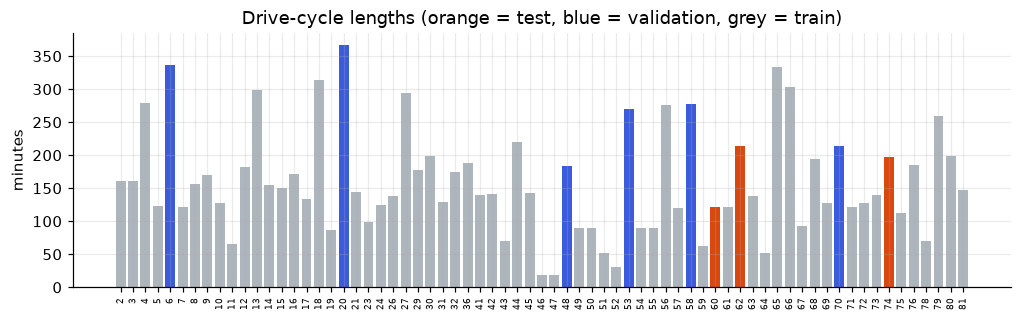

In [3]:
fig, ax = plt.subplots(figsize=(11, 3))
colors = ["#d9480f" if p in TEST_PROFILES else "#3b5bdb" if p in VAL_PROFILES else "#adb5bd" for p in dur_min.index]
ax.bar(dur_min.index.astype(str), dur_min.values, color=colors)
ax.set_ylabel("minutes"); ax.set_title("Drive-cycle lengths (orange = test, blue = validation, grey = train)")
ax.tick_params(axis="x", labelsize=6, rotation=90); plt.show()

### One drive cycle

Temperatures move **slowly** (time constants of many minutes) while speed and current change in seconds.
That mismatch is the whole modelling problem: the model must remember the motor's recent load history.

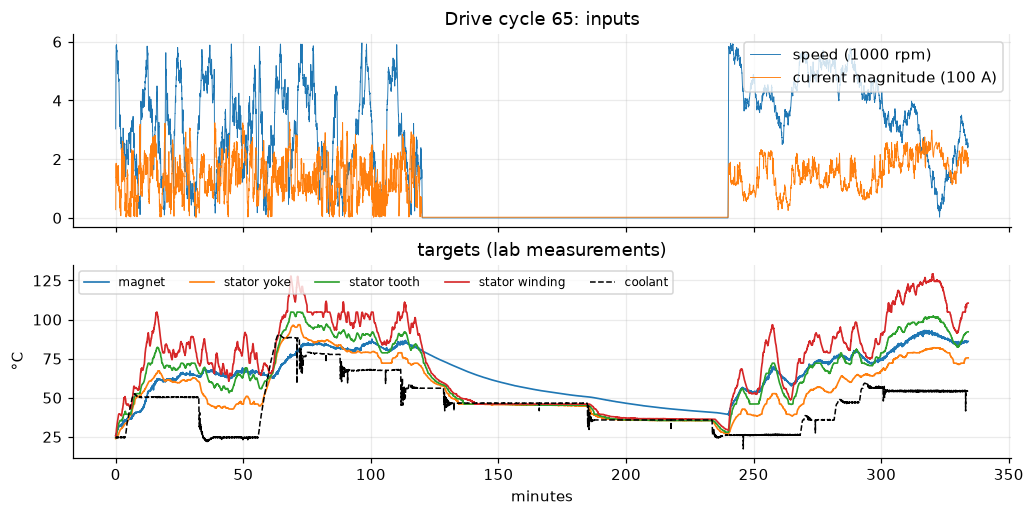

In [4]:
pid = int(dur_min[train_p].idxmax())             # longest training cycle
g = df[df.profile_id == pid].reset_index(drop=True); t = np.arange(len(g)) / SAMPLE_RATE_HZ / 60
fig, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
ax[0].plot(t, g.motor_speed / 1000, lw=.6, label="speed (1000 rpm)"); ax[0].plot(t, g.i_s / 100, lw=.6, label="current magnitude (100 A)")
ax[0].legend(loc="upper right"); ax[0].set_title(f"Drive cycle {pid}: inputs")
for c in TARGETS: ax[1].plot(t, g[c], lw=1.1, label=NAMES[c])
ax[1].plot(t, g.coolant, lw=1, ls="--", color="k", label="coolant"); ax[1].legend(loc="upper left", ncol=5, fontsize=8)
ax[1].set_ylabel("°C"); ax[1].set_xlabel("minutes"); ax[1].set_title("targets (lab measurements)"); plt.show()

**Look at minutes ~120 to 240:** the motor is stopped. The stator temperatures fall to the coolant within minutes, but the **magnet
cools far more slowly** (it sits on the rotor, away from the cooling jacket). If the car restarts during that window, the magnet is still
hot: this is the hot-restart problem examined in section 9.

## 2. Why load *history* matters (the key EDA insight)

Copper losses grow with current². The instantaneous current tells us almost nothing about the magnet temperature,
but an exponentially weighted average of the **recent** current does.

In [5]:
tr = df[df.profile_id.isin(train_p)]
rows = {"instantaneous": tr.i_s_sq}
for span, label in [(240, "2 min"), (1320, "11 min"), (3360, "28 min"), (6360, "53 min")]:
    rows[f"EWMA {label}"] = tr.groupby("profile_id").i_s_sq.transform(lambda s: s.ewm(span=span, adjust=False).mean())
corr = pd.Series({k: np.corrcoef(v, tr.pm - tr.coolant)[0, 1] for k, v in rows.items()}, name="corr with (magnet - coolant)")
corr.round(3).to_frame()

,corr with (magnet - coolant)
instantaneous,0.298
EWMA 2 min,0.361
EWMA 11 min,0.485
EWMA 28 min,0.561
EWMA 53 min,0.575


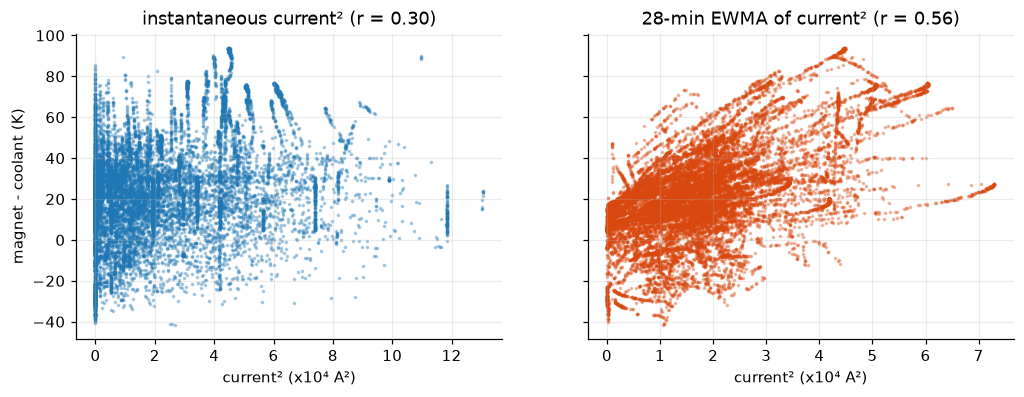

In [6]:
s = tr.sample(20000, random_state=0).index
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
ax[0].scatter(tr.loc[s, "i_s_sq"] / 1e4, (tr.pm - tr.coolant)[s], s=2, alpha=.3); ax[0].set_title(f"instantaneous current² (r = {corr.iloc[0]:.2f})")
ax[1].scatter(rows["EWMA 28 min"][s] / 1e4, (tr.pm - tr.coolant)[s], s=2, alpha=.3, color="#d9480f"); ax[1].set_title(f"28-min EWMA of current² (r = {corr['EWMA 28 min']:.2f})")
ax[0].set_ylabel("magnet - coolant (K)")
for a in ax: a.set_xlabel("current² (x10⁴ A²)")
plt.show()

## 3. Features

* **Physics features:** current magnitude, voltage magnitude, apparent power, current² (copper losses), power x speed (iron-loss proxy).
* **Load history:** exponentially weighted means *and* standard deviations over 7, 11, 28 and 53 minutes, computed **per drive cycle**
  and **causally** (only past samples, so no leakage from the future).
* **Rest-start padding:** before the first sample the motor is assumed *off* (electrical signals = 0). An earlier version repeated the
  first reading instead; a cycle starting at 5,700 rpm then looked as if it had been at full load forever (79 K error).

Span set, std features and ridge strength were chosen by grouped cross-validation on training cycles (`src/select_cv.py`):

In [7]:
cv = pd.DataFrame(json.loads((ROOT / "reports" / "cv_selection.json").read_text()))
cv.sort_values("cv_mse").head(6)[["model", "spans", "std", "alpha", "cv_mse", "cv_mse_pm"]].round(2)

,model,spans,std,alpha,cv_mse,cv_mse_pm
5,ridge,short (7–53 min),True,10.0,6.85,16.43
4,ridge,short (7–53 min),True,1.0,7.10,17.13
3,ridge,short (7–53 min),True,0.1,7.12,17.16
15,ridge,wide (4–79 min),True,0.1,7.25,17.47
17,ridge,wide (4–79 min),True,10.0,7.27,17.58
16,ridge,wide (4–79 min),True,1.0,7.27,17.55


In [8]:
t0 = time.time()
X, cols = make_features(raw, MEASURABLE, spans=SPAN_SETS["short (7–53 min)"], with_std=True)
print(f"{len(cols)} features in {time.time() - t0:.0f}s, e.g. {cols[:3]} ... {cols[-2:]}")

108 features in 4s, e.g. ['ambient', 'coolant', 'u_d'] ... ['i_s_sq_ews6360', 's_x_w_ews6360']


## 4. Validation strategy: why whole drive cycles must be held out

Rows 0.5 s apart are almost identical. A random K-fold split puts neighbouring rows in train and validation, so a flexible model
can "remember" the cycle and the score looks far better than it will be on a new drive. **GroupKFold by drive cycle** measures what
matters: generalisation to cycles the model has never seen. Demonstration on the training cycles (every 8th row, magnet target,
gradient boosting):

In [9]:
idx = np.flatnonzero(raw.profile_id.isin(train_p).to_numpy())[::8]
Xs, ys, gs = X.iloc[idx].to_numpy(np.float32), raw.pm.to_numpy()[idx], raw.profile_id.to_numpy()[idx]
model = lambda: HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, min_samples_leaf=100, random_state=0)
res = {}
for name, splitter in [("random KFold (leaks)", KFold(5, shuffle=True, random_state=0)), ("GroupKFold by cycle", GroupKFold(5))]:
    err = np.concatenate([model().fit(Xs[a], ys[a]).predict(Xs[b]) - ys[b] for a, b in splitter.split(Xs, ys, gs)])
    res[name] = round(float((err ** 2).mean()), 2)
pd.Series(res, name="magnet MSE (K²)").to_frame()

,magnet MSE (K²)
random KFold (leaks),0.55
GroupKFold by cycle,10.95


The random split looks about **20x better** than reality. That is exactly the trap of row-level splits on time series; every
choice in this project used whole-cycle splits.

## 5. Ridge regression on the load-history features

One ridge model per temperature (standardised features, alpha = 10), trained on the training cycles only (validation and
test cycles excluded). The test cycles are scored **once**.

In [10]:
is_tr = raw.profile_id.isin(train_p).to_numpy()
models = {t: ridge().fit(X[is_tr], raw.loc[is_tr, t]) for t in TARGETS}
order = lambda pids: pd.concat([df[df.profile_id == p] for p in pids])
def ridge_pred(pids):
    rows = np.concatenate([np.flatnonzero(raw.profile_id.to_numpy() == p) for p in pids])
    return np.column_stack([models[t].predict(X.iloc[rows]) for t in TARGETS])
d_te = order(TEST_PROFILES); Y_te = d_te[TARGETS].to_numpy(); pid_te = d_te.profile_id.to_numpy()
P_ridge = ridge_pred(TEST_PROFILES)
pd.DataFrame({"ridge (no start info)": score(P_ridge, Y_te)})

,ridge (no start info)
MSE avg (K²),2.35
MSE magnet (K²),4.03
worst case (K),13.23


## 6. Start-of-run correction

At the start of a cycle the averages have no history yet, so the regression is biased. If we know the temperature at start
(in a car: the estimate stored at the last shutdown), we remove that bias and let the correction fade:

$$\hat T(t) = f(x)(t) + \big(T_0 - f(x)(0)\big)\, e^{-t/\tau}$$

τ was chosen per target from out-of-fold predictions (`src/start_correction.py`): about 15 minutes for the magnet and 5 for the
stator, because the rotor is less directly cooled.

In [11]:
taus = list(json.loads((ROOT / "reports" / "start_correction.json").read_text())["tau_s"].values())
print("tau (s):", dict(zip(TARGETS, taus)))
d0 = d_te.reset_index(drop=True)
P_rc = {m: correct(P_ridge, pid_te, initial_temps(d0, m), taus) for m in ["known", "cold"]}
pd.DataFrame({"ridge": score(P_ridge, Y_te), "+ correction, cold start": score(P_rc["cold"], Y_te),
              "+ correction, known start": score(P_rc["known"], Y_te)})

tau (s): {'pm': 900, 'stator_yoke': 300, 'stator_tooth': 300, 'stator_winding': 300}


,ridge,"+ correction, cold start","+ correction, known start"
MSE avg (K²),2.35,2.37,2.09
MSE magnet (K²),4.03,4.61,3.60
worst case (K),13.23,11.19,7.76


## 7. Thermal Neural Network (physics-structured deep learning)

A lumped-parameter thermal network: four temperature nodes (magnet, yoke, tooth, winding) plus coolant and ambient as boundary
nodes. Small neural networks predict the **thermal conductances** G between nodes and the **power losses** P of each node; the
state is integrated every 0.5 s:

$$T_{k+1} = T_k + \Delta t\, e^{c} \Big(\sum_j G_{ij}\,(T_j - T_i) + P_i\Big)$$

Physics provides the structure (heat flows from hot to cold, losses are non-negative); data fills in the numbers. It has only
**537 parameters**. Trained in PyTorch with truncated back-propagation, alternating known and cold initial states, early-stopped on
validation cycles that include hot restarts. Several seeds were trained; the checkpoint is chosen on **validation**:

In [12]:
ckpts = sorted(ROOT.glob("models/tnn_seed*.pt"))
vals = {p.name: round(torch.load(p, weights_only=False)["val_score"], 2) for p in ckpts}
best = min(ckpts, key=lambda p: vals[p.name])
c = torch.load(best, weights_only=False)
cell = T.TNNCell(len(c["inputs"]), len(c["targets"]), [c["inputs"].index(b) for b in c["boundary"]])
print("validation score by checkpoint:", vals, "-> chosen:", best.name)
print("parameters:", sum(p.numel() for p in cell.parameters()))
P_tnn = {m: tnn_predict(best, df, TEST_PROFILES, m) for m in ["known", "cold"]}
pd.DataFrame({"TNN, cold start": score(P_tnn["cold"], Y_te), "TNN, known start": score(P_tnn["known"], Y_te)})

validation score by checkpoint: {'tnn_seed0.pt': 9.12, 'tnn_seed1.pt': 5.62, 'tnn_seed1_cont.pt': 4.14, 'tnn_seed2.pt': 6.07} -> chosen: tnn_seed1_cont.pt
parameters: 537


,"TNN, cold start","TNN, known start"
MSE avg (K²),2.85,2.70
MSE magnet (K²),3.77,3.20
worst case (K),8.33,8.51


## 8. Ensemble: why the average beats both models

The two models make **different kinds of mistakes**: a static regression on smoothed history versus a dynamic heat-flow
simulation. Averaging two estimates reduces the error whenever their errors are less than perfectly correlated, and the gain is
largest where they point in opposite directions.

In [13]:
P_ens = {m: (P_rc[m] + P_tnn[m]) / 2 for m in ["known", "cold"]}
e1, e2 = P_rc["known"] - Y_te, P_tnn["known"] - Y_te
print("error correlation (ridge+corr vs TNN):", {NAMES[t]: round(float(np.corrcoef(e1[:, j], e2[:, j])[0, 1]), 2) for j, t in enumerate(TARGETS)})
pd.DataFrame({"ridge + correction": score(P_rc["known"], Y_te), "TNN": score(P_tnn["known"], Y_te),
              "ENSEMBLE (known start)": score(P_ens["known"], Y_te), "ensemble (cold start)": score(P_ens["cold"], Y_te)})

error correlation (ridge+corr vs TNN): {'magnet': -0.18, 'stator yoke': 0.71, 'stator tooth': 0.52, 'stator winding': 0.4}


,ridge + correction,TNN,ENSEMBLE (known start),ensemble (cold start)
MSE avg (K²),2.09,2.70,1.50,1.72
MSE magnet (K²),3.60,3.20,1.37,2.17
worst case (K),7.76,8.51,5.73,7.38


For the **magnet** the two models' errors are negatively correlated (they err in opposite directions), so averaging cancels them and
the magnet MSE drops from 3.60 / 3.20 to 1.37 K². For the stator temperatures the errors are positively correlated (0.4 to 0.7) but
well below 1, so averaging still helps. The average beats both members on validation, where the choice was made, and on test.

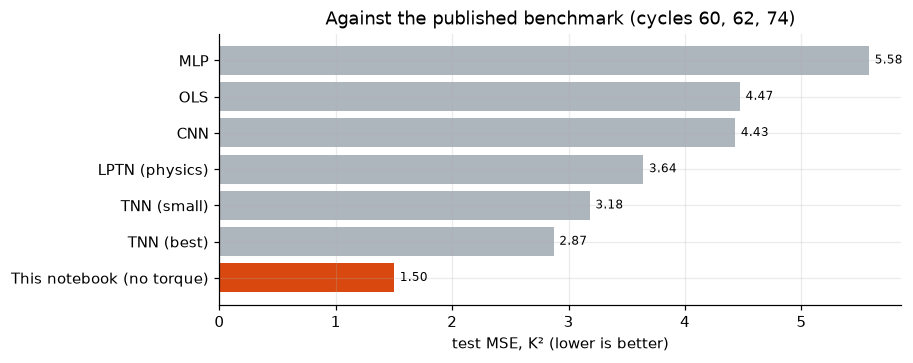

In [14]:
pub = PUBLISHED.set_index("model")["mse_avg"].to_dict()
pub["This notebook (no torque)"] = score(P_ens["known"], Y_te)["MSE avg (K²)"]
s = pd.Series(pub).sort_values()
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(s.index, s.values, color=["#d9480f" if "notebook" in i else "#adb5bd" for i in s.index])
for i, v in enumerate(s.values): ax.text(v + .05, i, f"{v:.2f}", va="center", fontsize=8)
ax.set_xlabel("test MSE, K² (lower is better)"); ax.set_title("Against the published benchmark (cycles 60, 62, 74)"); plt.show()

## 9. The finding the benchmark hides: hot restarts

All three official test cycles start with a **cool** motor. Real cars restart hot: drive, park for ten minutes, drive again.
Validation cycle 53 starts with the magnet 32 K above the coolant. What happens if the car assumes a cold start?

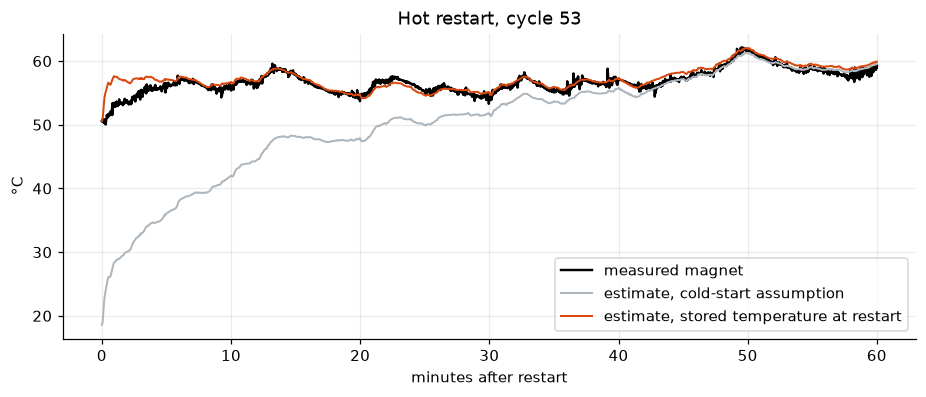

cold  start: worst magnet error in first hour  32.0 K, error above 3 K until minute 39
known start: worst magnet error in first hour   5.5 K, error above 3 K until minute 3


In [15]:
p = 53
d53 = order([p]).reset_index(drop=True); Y53 = d53[TARGETS].to_numpy(); pr = ridge_pred([p])
est = {m: (correct(pr, d53.profile_id.to_numpy(), initial_temps(d53, m), taus) + tnn_predict(best, df, [p], m)) / 2 for m in ["cold", "known"]}
t = np.arange(len(d53)) / SAMPLE_RATE_HZ / 60; w = t <= 60
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(t[w], Y53[w, 0], color="k", lw=1.6, label="measured magnet")
ax.plot(t[w], est["cold"][w, 0], color="#adb5bd", lw=1.3, label="estimate, cold-start assumption")
ax.plot(t[w], est["known"][w, 0], color="#d9480f", lw=1.3, label="estimate, stored temperature at restart")
ax.set_xlabel("minutes after restart"); ax.set_ylabel("°C"); ax.legend(); ax.set_title("Hot restart, cycle 53"); plt.show()
for m in ["cold", "known"]:
    err = np.abs(est[m][w, 0] - Y53[w, 0]); bad = np.flatnonzero(err > 3)
    print(f"{m:5s} start: worst magnet error in first hour {err.max():5.1f} K, error above 3 K until minute {(bad[-1] + 1) / SAMPLE_RATE_HZ / 60 if len(bad) else 0:.0f}")

**Engineering takeaway:** the controller must store its estimate at shutdown (ideally also model cooling while parked).

## 10. Error analysis on the test cycles

In [16]:
rows = []
for p in TEST_PROFILES:
    m = pid_te == p; e = P_ens["known"][m] - Y_te[m]
    rows.append({"cycle": p, "minutes": round(m.sum() / SAMPLE_RATE_HZ / 60), **{f"MSE {NAMES[t]}": round(float((e[:, j] ** 2).mean()), 2) for j, t in enumerate(TARGETS)},
                 "worst (K)": round(float(np.abs(e).max()), 2), "worst at": NAMES[TARGETS[int(np.abs(e).max(0).argmax())]]})
pd.DataFrame(rows).set_index("cycle")

,minutes,MSE magnet,MSE stator yoke,MSE stator tooth,MSE stator winding,worst (K),worst at
cycle,,,,,,,
60,121,1.00,0.74,1.54,1.75,4.91,stator winding
62,213,1.50,2.03,1.43,1.41,4.37,stator tooth
74,198,1.46,0.99,1.49,2.30,5.73,stator winding


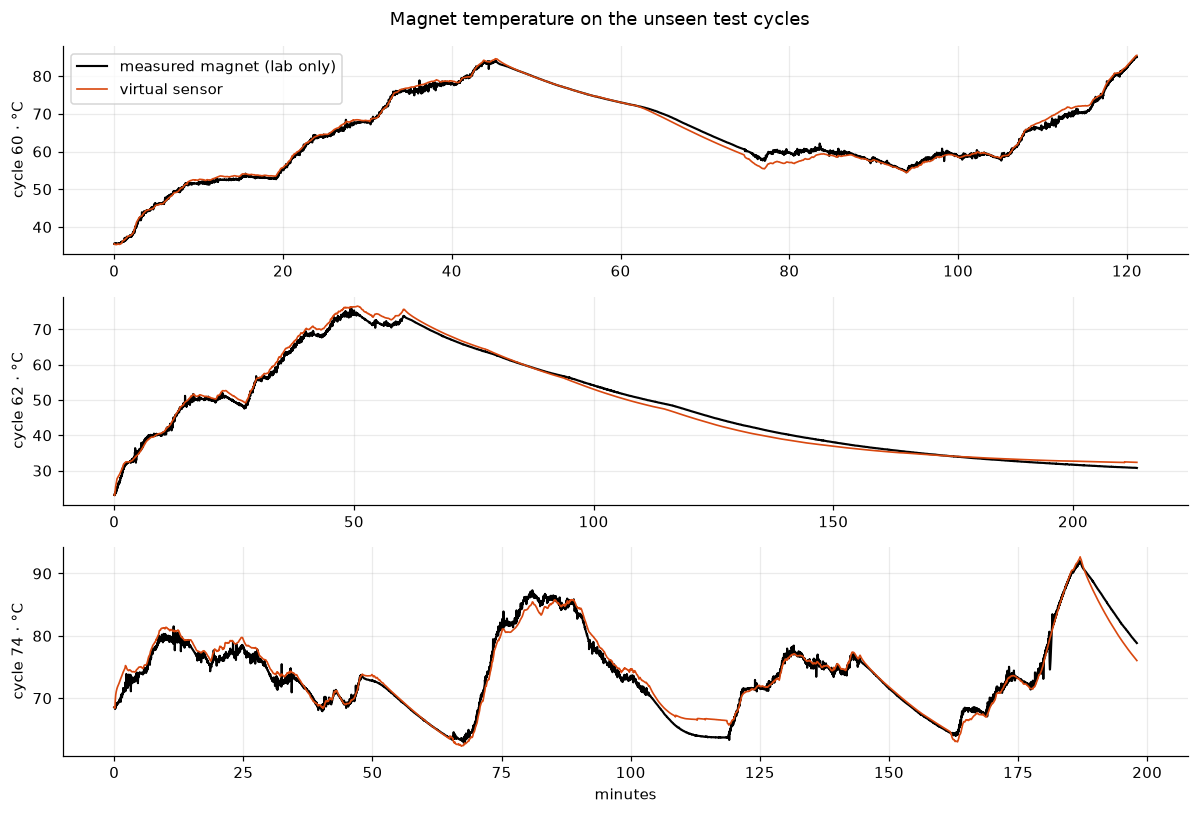

In [17]:
fig, ax = plt.subplots(3, 1, figsize=(11, 7.5), sharey=False)
for a, p in zip(ax, TEST_PROFILES):
    m = pid_te == p; tt = np.arange(m.sum()) / SAMPLE_RATE_HZ / 60
    a.plot(tt, Y_te[m, 0], color="k", lw=1.4, label="measured magnet (lab only)")
    a.plot(tt, P_ens["known"][m, 0], color="#d9480f", lw=1.1, label="virtual sensor")
    a.set_ylabel(f"cycle {p} · °C")
ax[0].legend(loc="upper left"); ax[-1].set_xlabel("minutes"); fig.suptitle("Magnet temperature on the unseen test cycles"); plt.tight_layout(); plt.show()

## 11. What did not work, limitations and next steps

**Did not work**
* Gradient boosting lost to ridge in grouped CV (8.54 vs 6.85 K²): with only ~50 training cycles, the simpler model generalised better.
* A plain GRU with an initial-state input (2.79 K², ~25 K worst case) learned to ignore its initial state.
* Repeating the first reading as pre-recording history: 79 K error on a cycle that starts at speed.

**Limitations:** one motor on one test bench; only three test cycles; headline accuracy assumes the stored start temperature
(cold start: 1.72 K²); at a 100 °C limit one cycle peaking at 102.1 °C is missed, so a deployed system needs a margin.

**Next:** model cool-down while parked, validate on a second motor, quantify uncertainty for a safety margin.

**Around the model (software):** the same model is packaged as a `VirtualSensor` class, used by a Streamlit app and by an LLM agent
that answers engineering questions through six tested tools; `pytest` and Node tests, a GitHub Actions pipeline (tests + Docker build
+ container health check) and a slim, non-root Docker image run on every push.